# Ensayo de irradiación de celdas solares: análisis de datos de la BBB

## Recopilación

In [13]:
#-----------------------------------CREO EL PATH Y ME FIJO QUE ESTEN TODOS LO ARCHIVOS---------------------------------------#
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

horas_de_margen_en_los_extremos = 3

columnas = ["fecha_hora", "voltage1", "voltage2", "estado_luz"]
carpeta = Path("Archivos")
carpeta_graficos = Path("Gráficos")
carpeta_graficos.mkdir(exist_ok=True)

archivos = sorted(carpeta.glob("*.txt"))
print(f"Archivos encontrados: {len(archivos)}")
print(f"Primero: {archivos[0].name}")
print(f"Último: {archivos[-1].name}")

Archivos encontrados: 2867
Primero: 2026-11-14_12-52-23.txt
Último: 2026-11-25_9-58-50.txt


In [14]:
#-----------------------------------LEO CADA ARCHIVO Y JUNTO TODO EN UN DATAFRAME---------------------------------------#
lista_de_dataframes = []            # Lista vacía donde guardo un DataFrame por archivo
archivos_con_problemas = []         # Lista de archivos que fallen al leerse

for archivo in archivos:            # Recorre los 2867 archivos, uno por vez
    try:
        df_archivo = pd.read_csv(
            archivo,
            header=None,
            names=columnas,
            skipinitialspace=True,
        )
    except Exception as error:
        archivos_con_problemas.append((archivo.name, str(error)))
        continue

    df_archivo["archivo"] = archivo.name
    lista_de_dataframes.append(df_archivo)

df = pd.concat(lista_de_dataframes, ignore_index=True)

print(f"Filas totales: {len(df)} (esperadas: {len(archivos) * 40})")
print(f"Archivos con problemas: {len(archivos_con_problemas)}")
# El primer archivo llegó vacío
print("Archivos que aportaron filas:", df["archivo"].nunique())
print("Archivos totales:", len(archivos))

Filas totales: 114640 (esperadas: 114680)
Archivos con problemas: 0
Archivos que aportaron filas: 2866
Archivos totales: 2867


In [15]:
#-----------------------------------CONVIERTO LA FECHA, ORDENO DATOS Y REVISO TIPADO---------------------------------------#
df["fecha_hora"] = pd.to_datetime(df["fecha_hora"], errors="coerce")

filas_con_fecha_invalida = df["fecha_hora"].isna().sum()
print(f"Fechas inválidas: {filas_con_fecha_invalida}")

df = df.sort_values("fecha_hora").reset_index(drop=True)

print(df.dtypes)
print()
print(df.head())
print()
print(df.tail())
print()
print(f"Desde {df['fecha_hora'].min()} hasta {df['fecha_hora'].max()}")


Fechas inválidas: 0
fecha_hora    datetime64[us]
voltage1              object
voltage2              object
estado_luz            object
archivo                  str
dtype: object

               fecha_hora voltage1 voltage2 estado_luz  \
0 2026-11-14 12:58:15.660   1.1042   1.4954          1   
1 2026-11-14 12:58:22.991    1.076   0.4998          1   
2 2026-11-14 12:58:30.986   1.0822   0.5002          1   
3 2026-11-14 12:58:38.990   1.0826   0.4927          1   
4 2026-11-14 12:58:47.107   1.0853   0.4892          1   

                   archivo  
0  2026-11-14_12-58-15.txt  
1  2026-11-14_12-58-15.txt  
2  2026-11-14_12-58-15.txt  
3  2026-11-14_12-58-15.txt  
4  2026-11-14_12-58-15.txt  

                    fecha_hora voltage1 voltage2 estado_luz  \
114635 2026-11-25 19:45:01.634   1.1095   0.4765          1   
114636 2026-11-25 19:45:09.638   1.1125   0.4949          1   
114637 2026-11-25 19:45:17.640    1.109   0.4277          1   
114638 2026-11-25 19:45:25.650   1.1125   0.

In [16]:
#-----------------------------------EXPLORO LAS COLUMNAS TIPO "OBJECT"---------------------------------------#

for columna in ["voltage1", "voltage2", "estado_luz"]:
    convertido = pd.to_numeric(df[columna], errors="coerce")
    filas_no_numericas = df[convertido.isna()]

    print(f"--- {columna}: {len(filas_no_numericas)} valores no numéricos ---")
    print(filas_no_numericas[columna].value_counts().head(10))
    print()
    print(filas_no_numericas["archivo"].value_counts().head(5))
    print()
    # NO HAY ARCHIVOS DAÑADOS, PUEDO CONVERTIR

--- voltage1: 0 valores no numéricos ---
Series([], Name: count, dtype: int64)

Series([], Name: count, dtype: int64)

--- voltage2: 0 valores no numéricos ---
Series([], Name: count, dtype: int64)

Series([], Name: count, dtype: int64)

--- estado_luz: 0 valores no numéricos ---
Series([], Name: count, dtype: int64)

Series([], Name: count, dtype: int64)



In [17]:
#-----------------------------------CONVIERTO A NUMÉRICO---------------------------------------#

df["voltage1"] = pd.to_numeric(df["voltage1"])
df["voltage2"] = pd.to_numeric(df["voltage2"])
df["estado_luz"] = pd.to_numeric(df["estado_luz"]).astype(int)

print(df.dtypes)
print()
print(df[["voltage1", "voltage2", "estado_luz"]].describe())
print()
print(df["estado_luz"].value_counts())
print()
print("Valores faltantes por columna:")
print(df.isna().sum())

fecha_hora    datetime64[us]
voltage1             float64
voltage2             float64
estado_luz             int64
archivo                  str
dtype: object

            voltage1       voltage2     estado_luz
count  114640.000000  114640.000000  114640.000000
mean        1.093932       0.241889       0.500462
std         0.027902       0.239497       0.500002
min         0.000000       0.000000       0.000000
25%         1.085300       0.002200       0.000000
50%         1.098500       0.038200       1.000000
75%         1.106800       0.477800       1.000000
max         1.353000       1.750300       1.000000

estado_luz
1    57373
0    57267
Name: count, dtype: int64

Valores faltantes por columna:
fecha_hora    0
voltage1      0
voltage2      0
estado_luz    0
archivo       0
dtype: int64


In [18]:
#-----------------------------------EXPLORO CORTES EN LA ADQUISICIÓN DE DATOS---------------------------------------#

df["segundos_desde_anterior"] = df["fecha_hora"].diff().dt.total_seconds()

print(df["segundos_desde_anterior"].describe())
print()
print("Los 10 saltos más grandes:")
saltos_grandes = df.nlargest(10, "segundos_desde_anterior")
print(saltos_grandes[["fecha_hora", "segundos_desde_anterior", "archivo"]])

count    114639.000000
mean          8.503546
std         148.768997
min           4.066000
25%           7.998000
50%           8.003000
75%           8.008000
max       50067.395000
Name: segundos_desde_anterior, dtype: float64

Los 10 saltos más grandes:
                   fecha_hora  segundos_desde_anterior  \
24745 2026-11-17 11:24:10.558                50067.395   
42    2026-11-14 14:34:14.884                 5431.718   
25202 2026-11-17 12:56:41.462                 1322.058   
25120 2026-11-17 12:23:51.887                  287.767   
24760 2026-11-17 11:29:48.213                  225.802   
24987 2026-11-17 12:01:27.790                   89.100   
24680 2026-11-16 21:21:10.975                   51.826   
95479 2026-11-24 01:10:01.708                   13.909   
290   2026-11-14 15:07:25.750                   12.088   
95481 2026-11-24 01:10:17.621                   11.102   

                       archivo  
24745  2026-11-16_21-26-31.txt  
42      2026-11-14_13-3-35.txt  
2520

Cortes en la adquisición:
* 50067 seg => 13,9 horas \\ alrededor de las 21:29 del 16/11 y volvió a las 11:24 del 17/11 (traslado UTN a CNEA)
* 5431 seg => 1,5 horas   \\ alrededor de las 13:34 del 14/11 y volvió a las 14:34 del 14/11.
* 1322 seg => 22 minutos  \\ alrededor de las 12:34 del 17/11 y volvió a las 12:56 del 17/11.
* Los demas cortes son menores a los 5 minutos.

Con esta información conviene establecer dos ventanas:
* Sin radiación: Desde 14/11 12:58 hasta el 16/11 21:29.
* Con radiación: Desde 17/11 11:24 hasta el 25/11 19:45.

In [19]:
#-----------------------------------CORRIENTE EN LA RESISTENCIA DE CARGA---------------------------------------#
resistencia_de_carga_ohm = 74.3e3   # 74,3 kΩ en paralelo con la celda

# I = V / R, expresada en microamperios
df["corriente_uA"] = df["voltage2"] / resistencia_de_carga_ohm * 1e6

print(df[["voltage2", "corriente_uA"]].describe())

#-----------------------------------FUNCIÓN PARA MARCAR BLOQUES---------------------------------------#
def agregar_bloques(datos):
    datos = datos.copy()

    # Segundos que pasaron desde la muestra anterior
    datos["segundos_desde_anterior"] = datos["fecha_hora"].diff().dt.total_seconds()

    # Un bloque nuevo empieza si hay un corte (más de 20 s sin datos)
    # o si la luz cambió de estado
    datos["hay_corte"] = datos["segundos_desde_anterior"] > 20
    datos["cambio_de_estado"] = datos["estado_luz"] != datos["estado_luz"].shift()
    datos["nuevo_bloque"] = datos["hay_corte"] | datos["cambio_de_estado"]

    # Número de bloque: se suma uno cada vez que empieza un bloque nuevo
    datos["numero_de_bloque"] = datos["nuevo_bloque"].cumsum()

    # Minutos transcurridos desde el inicio de su bloque
    inicio_de_cada_bloque = datos.groupby("numero_de_bloque")["fecha_hora"].transform("first")
    diferencia = datos["fecha_hora"] - inicio_de_cada_bloque
    datos["minutos_desde_inicio_de_bloque"] = diferencia.dt.total_seconds() / 60

    return datos
#-----------------------------------SEPARO VENTANAS---------------------------------------#
# Entre las dos ventanas no hay datos (traslado de la UTN a la CNEA),
# así que alcanza con cortar en la medianoche del 17/11.
corte_entre_ventanas = pd.Timestamp("2026-11-17 00:00:00")

df_sin_radiacion = df[df["fecha_hora"] < corte_entre_ventanas].copy()
df_con_radiacion = df[df["fecha_hora"] >= corte_entre_ventanas].copy()

print(f"Sin radiación: {len(df_sin_radiacion)} filas")
print(f"Con radiación: {len(df_con_radiacion)} filas")
print(f"Total: {len(df_sin_radiacion) + len(df_con_radiacion)} filas")

df_sin_radiacion = agregar_bloques(df_sin_radiacion)
df_con_radiacion = agregar_bloques(df_con_radiacion)

            voltage2   corriente_uA
count  114640.000000  114640.000000
mean        0.241889       3.255566
std         0.239497       3.223383
min         0.000000       0.000000
25%         0.002200       0.029610
50%         0.038200       0.514132
75%         0.477800       6.430686
max         1.750300      23.557201
Sin radiación: 24745 filas
Con radiación: 89895 filas
Total: 114640 filas


## Gráficos

### Muestras crudas

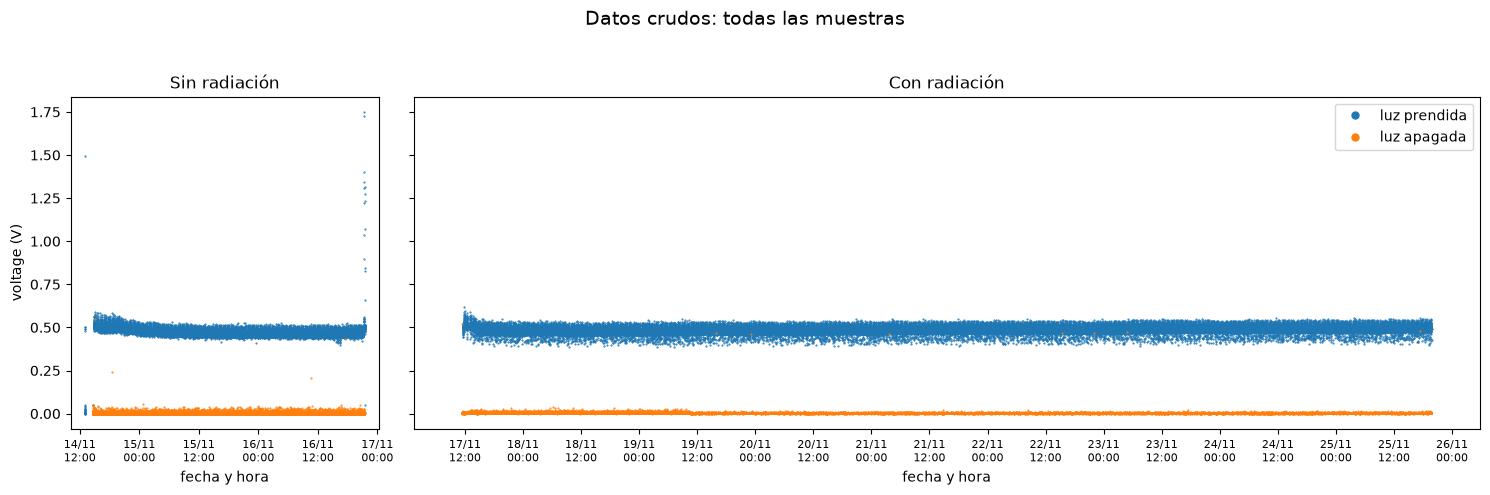

In [20]:
#-------------------------------- GRAFICO---------------------------------------#
figura, ejes = plt.subplots(
    1, 2, figsize=(15, 5), sharey=True,
    gridspec_kw={"width_ratios": [2.4, 8.3]},
)

ventanas = [
    ("Sin radiación", df_sin_radiacion, ejes[0]),
    ("Con radiación", df_con_radiacion, ejes[1]),
]

for titulo, datos, eje in ventanas:
    luz_prendida = datos[datos["estado_luz"] == 1]
    luz_apagada = datos[datos["estado_luz"] == 0]

    eje.plot(luz_prendida["fecha_hora"], luz_prendida["voltage2"],
             linestyle="none", marker=".", markersize=1, label="luz prendida")
    eje.plot(luz_apagada["fecha_hora"], luz_apagada["voltage2"],
             linestyle="none", marker=".", markersize=1, label="luz apagada")
    eje.set_title(titulo)
    eje.set_xlabel("fecha y hora")

ejes[0].set_ylabel("voltage (V)")
ejes[1].legend(markerscale=10)

ejes[0].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ejes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ejes[1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ejes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))

for eje in ejes:
    eje.tick_params(axis="x", labelsize=8)

figura.suptitle("Datos crudos: todas las muestras", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
#figura.savefig(carpeta_graficos / "Datos_crudos.png", dpi=200, bbox_inches="tight")
plt.show()

#### Observaciones sobre los datos crudos

Se definieron dos ventanas: **sin radiación** (14/11 12:58 a 16/11 21:29, en la UTN) y **con radiación** (17/11 11:24 a 25/11 19:45, en la CNEA). El traslado (unas 13,9 h sin datos) queda fuera de las dos. Las muestras se tomaron cada 8 s, con ciclos de 8 min de luz prendida y 8 min apagada, para evitar el sobrecalentamiento.

**Qué permite ver este gráfico**
- La adquisición fue continua en las dos ventanas, con pocos cortes.
- El orden de magnitud de la señal: con luz prendida `voltage2` ronda los 0,5 V y con luz apagada queda cerca de 0 V, es decir que la celda responde a la luz.
- No hay cambios bruscos: durante la irradiación no se ve ninguna caída repentina de la tensión.
- Los valores atípicos puntuales: un punto aislado cerca de 1,5 V al inicio de la ventana sin radiación y una tanda de valores entre 0,65 y 1,75 V en las horas previas al traslado. Hay que filtrarlos antes de promediar.
- La variación dentro de los ciclos, que aparece como una banda ancha (de ~0,1 V) con luz prendida.

**Qué no permite ver**
- **Tendencias lentas y pequeñas.** Con más de 114 mil puntos superpuestos y una banda ancha por la variación de cada ciclo, un cambio de algunas decenas de mV a lo largo de días queda tapado.
- **Cómo cambia la tensión dentro de un ciclo.** Esa forma queda comprimida dentro de la banda.
- **Cuántos puntos hay en cada zona.** Los puntos se superponen y no se distingue la densidad.
- **La degradación de la celda.** La medición es con carga fija, o sea un solo punto de operación, y no incluye corriente: no permite hablar del punto de máxima potencia ni de la corriente de cortocircuito. Tampoco hay sensor de temperatura para separar el efecto térmico del de la celda.
- **Una comparación directa entre ventanas.** Se midieron en lugares y condiciones distintas, así que la diferencia entre los dos paneles no se puede atribuir solo a la radiación.

Para ver tendencias hace falta resumir cada ciclo, que es lo que hace el gráfico siguiente.

### Grupos medianos
Ciclos de 8 minutos tomados al inicio, a la mitas y mas cerca del final.


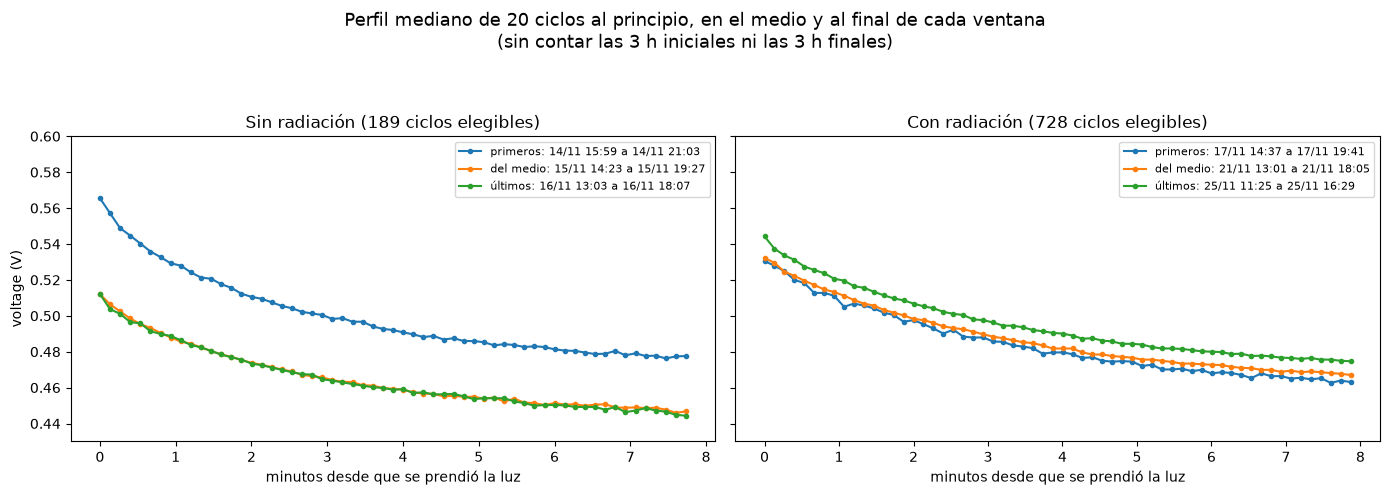

In [21]:
def dibujar_perfiles_medianos(eje, datos, titulo, ciclos_por_grupo=20,
                              horas_de_margen=horas_de_margen_en_los_extremos):
    inicio_de_la_ventana = datos["fecha_hora"].min()
    fin_de_la_ventana = datos["fecha_hora"].max()
    margen = pd.Timedelta(hours=horas_de_margen)
    limite_inferior = inicio_de_la_ventana + margen
    limite_superior = fin_de_la_ventana - margen

    resumen_de_bloques = datos.groupby("numero_de_bloque").agg(
        estado=("estado_luz", "first"),
        muestras=("estado_luz", "size"),
        inicio=("fecha_hora", "min"),
        fin=("fecha_hora", "max"),
    )

    es_prendida = resumen_de_bloques["estado"] == 1
    es_completo = resumen_de_bloques["muestras"] >= 55
    empieza_despues_del_margen = resumen_de_bloques["inicio"] >= limite_inferior
    termina_antes_del_margen = resumen_de_bloques["fin"] <= limite_superior

    condicion = es_prendida & es_completo & empieza_despues_del_margen & termina_antes_del_margen
    bloques_elegibles = resumen_de_bloques[condicion].index.tolist()

    cantidad_de_ciclos = len(bloques_elegibles)
    posicion_inicial_del_medio = cantidad_de_ciclos // 2 - ciclos_por_grupo // 2

    grupos = [
        ("primeros", bloques_elegibles[:ciclos_por_grupo]),
        ("del medio", bloques_elegibles[posicion_inicial_del_medio:posicion_inicial_del_medio + ciclos_por_grupo]),
        ("últimos", bloques_elegibles[-ciclos_por_grupo:]),
    ]

    for nombre_del_grupo, numeros_de_bloque in grupos:
        filas_del_grupo = datos[datos["numero_de_bloque"].isin(numeros_de_bloque)].copy()

        filas_del_grupo["posicion"] = filas_del_grupo.groupby("numero_de_bloque").cumcount()
        muestras_del_ciclo_mas_corto = filas_del_grupo.groupby("numero_de_bloque").size().min()
        filas_del_grupo = filas_del_grupo[filas_del_grupo["posicion"] < muestras_del_ciclo_mas_corto]

        perfil = filas_del_grupo.groupby("posicion").agg(
            minutos=("minutos_desde_inicio_de_bloque", "median"),
            tension=("voltage2", "median"),
        )

        fecha_del_primer_ciclo = inicio_del_bloque = resumen_de_bloques.loc[numeros_de_bloque[0], "inicio"]
        fecha_del_ultimo_ciclo = resumen_de_bloques.loc[numeros_de_bloque[-1], "inicio"]
        etiqueta = (f"{nombre_del_grupo}: {fecha_del_primer_ciclo:%d/%m %H:%M} "
                    f"a {fecha_del_ultimo_ciclo:%d/%m %H:%M}")

        eje.plot(perfil["minutos"], perfil["tension"], marker=".", label=etiqueta)

    eje.set_title(f"{titulo} ({cantidad_de_ciclos} ciclos elegibles)")
    eje.set_xlabel("minutos desde que se prendió la luz")
    eje.legend(fontsize=8)


figura, ejes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

dibujar_perfiles_medianos(ejes[0], df_sin_radiacion, "Sin radiación")
dibujar_perfiles_medianos(ejes[1], df_con_radiacion, "Con radiación")

ejes[0].set_ylabel("voltage (V)")
ejes[0].set_ylim(0.43, 0.60)

figura.suptitle(
    "Perfil mediano de 20 ciclos al principio, en el medio y al final de cada ventana\n"
    f"(sin contar las {horas_de_margen_en_los_extremos} h iniciales ni las {horas_de_margen_en_los_extremos} h finales)",
    fontsize=13,
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
#figura.savefig(carpeta_graficos / "Tres_ciclos_grupo_mediano.png", dpi=200, bbox_inches="tight")
plt.show()

#### Observaciones sobre los ciclos individuales

Se eligieron 20 ciclos de luz prendida por ventana y se armó el perfil mediano: 20 de las primeras, 20 del medio y 20 de las últimas, sin contar las 3 h iniciales ni las 3 h finales de cada ventana (para evitar los datos anómalos de los extremos).

**Qué permite ver este gráfico**
- La forma de un ciclo: la tensión baja durante los 8 min de luz prendida, unos 50 a 60 mV, y la caída se repite en los tres ciclos de las dos ventanas.
- El transitorio inicial: el primer ciclo de cada ventana está más alto que los otros dos, podría ser artefacto de la temperatura.
- Que, pasado el transitorio, los ciclos de distintos días se parecen mucho, en ambas ventanas el del medio y el último casi se superponen.
- Hay un comportamiento según nuestra hipotesis en la ventana sin radiación que la otra rompe, en el momento de mayor temperatura de la celda es donde mayor tensión se registra.

**Qué no permite ver**
- **La causa del comportamiento.** En la no irradiada puede ser el calentamiento de la celda o la pérdida de flujo luminoso de la lámpara, y sin sensor de temperatura ni de irradiancia no se pueden separar. Aun más extraño es el comportamiento de la irradiada aumentando su voltage.


### Resumir ciclos
A cada ciclo se le asigna un valor representativo, su mediana.

Sin radiación: 0 ciclos descartados por tensión menor a 0.3 V
Con radiación: 0 ciclos descartados por tensión menor a 0.3 V
Ciclos sin radiación: 190
Ciclos con radiación: 728

       v_minuto_1_a_2  v_minuto_7_a_8  caida_en_el_ciclo
count      190.000000      190.000000         190.000000
mean         0.487740        0.453007           0.034733
std          0.012761        0.010322           0.003827
min          0.476000        0.428600           0.026300
25%          0.480000        0.447000           0.032100
50%          0.482200        0.449000           0.033900
75%          0.489375        0.454400           0.036900
max          0.523100        0.481800           0.050100

       v_minuto_1_a_2  v_minuto_7_a_8  caida_en_el_ciclo
count      728.000000      728.000000         728.000000
mean         0.503730        0.467436           0.036294
std          0.006567        0.005022           0.004391
min          0.434700        0.454500          -0.032600
25%          0.499800   

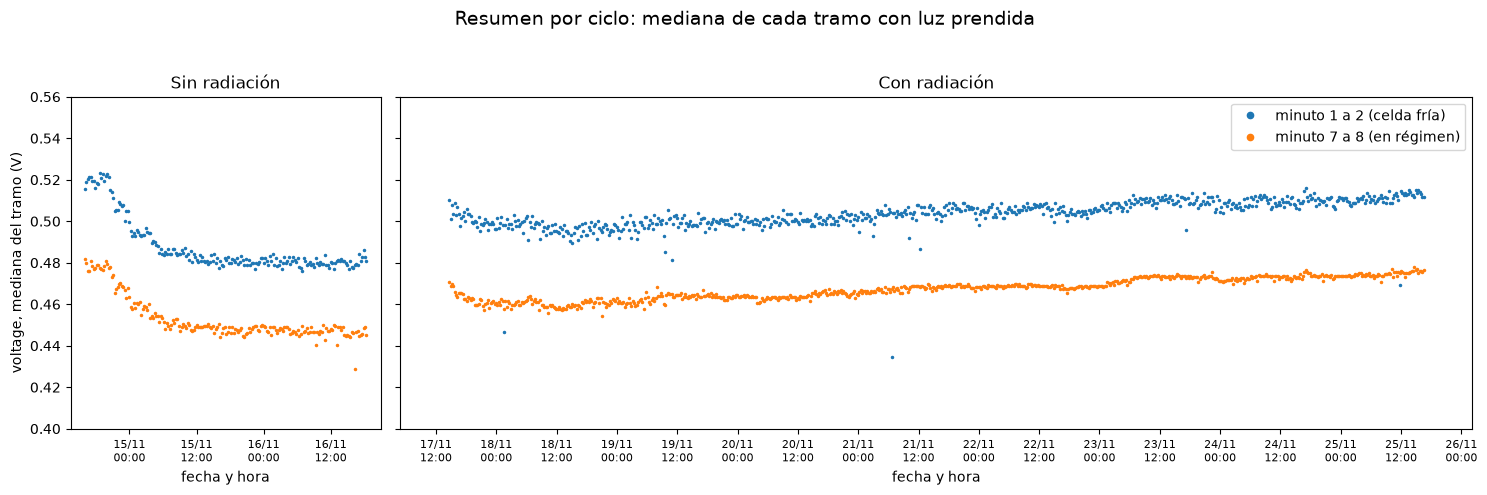

In [22]:
def resumir_ciclos_de_luz_prendida(datos):
    solo_luz_prendida = datos[datos["estado_luz"] == 1]
    filas_del_resumen = []

    for numero_de_bloque, bloque in solo_luz_prendida.groupby("numero_de_bloque"):
        if len(bloque) < 55:
            continue

        minutos = bloque["minutos_desde_inicio_de_bloque"]
        tramo_minuto_1_a_2 = bloque[(minutos >= 1) & (minutos < 2)]
        tramo_minuto_7_en_adelante = bloque[minutos >= 7]

        fila = {
            "numero_de_bloque": numero_de_bloque,
            "inicio": bloque["fecha_hora"].iloc[0],
            "v_minuto_1_a_2": tramo_minuto_1_a_2["voltage2"].median(),
            "v_minuto_7_a_8": tramo_minuto_7_en_adelante["voltage2"].median(),
        }
        filas_del_resumen.append(fila)

    resumen = pd.DataFrame(filas_del_resumen)
    resumen["caida_en_el_ciclo"] = resumen["v_minuto_1_a_2"] - resumen["v_minuto_7_a_8"]
    return resumen

def recortar_extremos(ciclos, datos, horas_de_margen=horas_de_margen_en_los_extremos):
    inicio_de_la_ventana = datos["fecha_hora"].min()
    fin_de_la_ventana = datos["fecha_hora"].max()
    margen = pd.Timedelta(hours=horas_de_margen)

    empieza_despues_del_margen = ciclos["inicio"] >= inicio_de_la_ventana + margen
    empieza_antes_del_margen_final = ciclos["inicio"] <= fin_de_la_ventana - margen

    ciclos_recortados = ciclos[empieza_despues_del_margen & empieza_antes_del_margen_final]
    return ciclos_recortados.copy().reset_index(drop=True)


def descartar_ciclos_invalidos(ciclos, nombre_de_la_ventana, tension_minima=0.3):
    primera_mediana_valida = ciclos["v_minuto_1_a_2"] >= tension_minima
    segunda_mediana_valida = ciclos["v_minuto_7_a_8"] >= tension_minima
    es_valido = primera_mediana_valida & segunda_mediana_valida

    ciclos_descartados = ciclos[~es_valido]
    print(f"{nombre_de_la_ventana}: {len(ciclos_descartados)} ciclos descartados "
          f"por tensión menor a {tension_minima} V")
    if len(ciclos_descartados) > 0:
        print(ciclos_descartados[["inicio", "v_minuto_1_a_2", "v_minuto_7_a_8"]])
        print()

    return ciclos[es_valido].copy().reset_index(drop=True)


ciclos_sin_radiacion = resumir_ciclos_de_luz_prendida(df_sin_radiacion)
ciclos_con_radiacion = resumir_ciclos_de_luz_prendida(df_con_radiacion)

ciclos_sin_radiacion = recortar_extremos(ciclos_sin_radiacion, df_sin_radiacion)
ciclos_con_radiacion = recortar_extremos(ciclos_con_radiacion, df_con_radiacion)

ciclos_sin_radiacion = descartar_ciclos_invalidos(ciclos_sin_radiacion, "Sin radiación")
ciclos_con_radiacion = descartar_ciclos_invalidos(ciclos_con_radiacion, "Con radiación")

print(f"Ciclos sin radiación: {len(ciclos_sin_radiacion)}")
print(f"Ciclos con radiación: {len(ciclos_con_radiacion)}")
print()
print(ciclos_sin_radiacion[["v_minuto_1_a_2", "v_minuto_7_a_8", "caida_en_el_ciclo"]].describe())
print()
print(ciclos_con_radiacion[["v_minuto_1_a_2", "v_minuto_7_a_8", "caida_en_el_ciclo"]].describe())

figura, ejes = plt.subplots(
    1, 2, figsize=(15, 5), sharey=True,
    gridspec_kw={"width_ratios": [2.4, 8.3]},
)

ventanas = [
    ("Sin radiación", ciclos_sin_radiacion, ejes[0]),
    ("Con radiación", ciclos_con_radiacion, ejes[1]),
]

for titulo, ciclos, eje in ventanas:
    eje.plot(ciclos["inicio"], ciclos["v_minuto_1_a_2"],
             linestyle="none", marker=".", markersize=3, label="minuto 1 a 2 (celda fría)")
    eje.plot(ciclos["inicio"], ciclos["v_minuto_7_a_8"],
             linestyle="none", marker=".", markersize=3, label="minuto 7 a 8 (en régimen)")
    eje.set_title(titulo)
    eje.set_xlabel("fecha y hora")

ejes[0].set_ylabel("voltage, mediana del tramo (V)")
ejes[1].legend(markerscale=3)

ejes[0].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ejes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))

ejes[1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ejes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))

for eje in ejes:
    eje.tick_params(axis="x", labelsize=8)

figura.suptitle(
    "Resumen por ciclo: mediana de cada tramo con luz prendida",
    fontsize=14,
)

ejes[0].set_ylim(0.40, 0.56)

plt.tight_layout(rect=[0, 0, 1, 0.95])
#figura.savefig(carpeta_graficos / "Resumen_por_ciclo.png", dpi=200, bbox_inches="tight")
plt.show()

#### Observaciones sobre el resumen por ciclo

Cada punto resume un ciclo de 8 min con luz prendida, con la mediana de la tensión entre el minuto 1 y 2 (celda fría) y entre el minuto 7 y 8 (en régimen). Se excluyeron las 2 h iniciales y finales de cada ventana y un ciclo sin radiación (14/11 15:00) cuya tensión cayó a ~0 V a mitad del tramo, con la luz prendida. Quedaron 197 ciclos sin radiación y 736 con radiación.

**Qué permite ver este gráfico**
- La tendencia lenta que el gráfico de datos crudos tapaba.
- El transitorio inicial: en la ventana sin radiación la tensión baja durante casi un día antes de estabilizarse, y con radiación el transitorio dura pocas horas.
- Con radiación, después del transitorio, la tensión sube de forma sostenida y pareja en las dos series (minuto 1 a 2 y minuto 7 a 8). No se observa degradación en el punto de operación medido.
- Que la caída dentro del ciclo es estable en el tiempo y similar en las dos ventanas (~35 mV entre las medianas del minuto 1 a 2 y del minuto 7 a 8).

**Qué no permite ver**
- **La causa del aumento.** Puede venir de la temperatura de la sala, del envejecimiento de la lámpara, de la deriva de la medición o de un efecto de la irradiación, y estos datos no permiten separarlas.
- **La degradación en términos de potencia.** Se mide a carga fija, o sea un solo punto de operación y sin corriente, así que no se puede hablar del punto de máxima potencia ni de la corriente de cortocircuito.
- **Una comparación directa entre ventanas.** Se midieron en lugares y con condiciones distintas, y la ventana sin radiación dura solo 2,4 días.
- **La incertidumbre real de la tendencia.** Los ciclos consecutivos no son independientes, así que los intervalos de confianza de los ajustes son optimistas.

#### Pendientes

In [23]:
from scipy import stats

ajustes = [
    ("Sin radiación", ciclos_sin_radiacion, pd.Timestamp("2026-11-15 12:00")),
    ("Con radiación", ciclos_con_radiacion, pd.Timestamp("2026-11-18 12:00")),
]
columnas_a_ajustar = ["v_minuto_1_a_2", "v_minuto_7_a_8"]

for nombre, ciclos, inicio_del_ajuste in ajustes:
    estables = ciclos[ciclos["inicio"] >= inicio_del_ajuste].dropna()

    segundos_desde_el_primero = (estables["inicio"] - estables["inicio"].iloc[0]).dt.total_seconds()
    dias = segundos_desde_el_primero / 86400
    duracion_en_dias = dias.iloc[-1]

    print(f"--- {nombre}: desde {inicio_del_ajuste}, {len(estables)} ciclos, {duracion_en_dias:.1f} días ---")

    for columna in columnas_a_ajustar:
        tension = estables[columna]

        ajuste_minimos_cuadrados = stats.linregress(dias, tension)
        pendiente_mv_por_dia = ajuste_minimos_cuadrados.slope * 1000
        error_mv_por_dia = ajuste_minimos_cuadrados.stderr * 1000

        pendiente_robusta, _, pendiente_baja, pendiente_alta = stats.theilslopes(tension, dias)
        pendiente_robusta_mv_por_dia = pendiente_robusta * 1000

        cambio_total_mv = pendiente_robusta_mv_por_dia * duracion_en_dias

        print(f"{columna}:")
        print(f"  mínimos cuadrados: {pendiente_mv_por_dia:+.2f} ± {error_mv_por_dia:.2f} mV/día")
        print(f"  Theil-Sen:         {pendiente_robusta_mv_por_dia:+.2f} mV/día "
              f"(intervalo {pendiente_baja * 1000:+.2f} a {pendiente_alta * 1000:+.2f})")
        print(f"  cambio total estimado: {cambio_total_mv:+.1f} mV en {duracion_en_dias:.1f} días")
    print()

--- Sin radiación: desde 2026-11-15 12:00:00, 114 ciclos, 1.3 días ---
v_minuto_1_a_2:
  mínimos cuadrados: -0.72 ± 0.47 mV/día
  Theil-Sen:         -0.73 mV/día (intervalo -1.76 a -0.00)
  cambio total estimado: -0.9 mV en 1.3 días
v_minuto_7_a_8:
  mínimos cuadrados: -2.41 ± 0.63 mV/día
  Theil-Sen:         -1.84 mV/día (intervalo -2.79 a -0.86)
  cambio total estimado: -2.3 mV en 1.3 días

--- Con radiación: desde 2026-11-18 12:00:00, 647 ciclos, 7.2 días ---
v_minuto_1_a_2:
  mínimos cuadrados: +2.27 ± 0.08 mV/día
  Theil-Sen:         +2.27 mV/día (intervalo +2.18 a +2.36)
  cambio total estimado: +16.3 mV en 7.2 días
v_minuto_7_a_8:
  mínimos cuadrados: +2.16 ± 0.03 mV/día
  Theil-Sen:         +2.14 mV/día (intervalo +2.09 a +2.20)
  cambio total estimado: +15.4 mV en 7.2 días



## Temperatura

Archivos de temperatura: 2444
Filas: 24440
Primera: 2026-11-16 23:58:39
Última:  2026-11-26 00:08:06
Tiempo típico entre muestras: 30 s
Huecos de más de 10 min: 7
Datos faltantes por columna:
T      237
T1       0
T2    1582
T3    1655
dtype: int64
                  T            T1            T2            T3
count  24203.000000  24440.000000  22858.000000  22785.000000
mean      27.097120     27.961412     27.272390     27.016722
std        0.792448      1.316610      1.001773      0.791220
min       24.100000     24.000000     24.000000     24.100000
25%       26.600000     27.400000     26.600000     26.500000
50%       27.100000     28.300000     27.100000     27.100000
75%       27.600000     28.800000     28.000000     27.600000
max       29.400000     30.300000     29.700000     28.800000
Hueco de 15 min que termina en 2026-11-17 11:58:54
Hueco de 36 min que termina en 2026-11-17 12:35:56
Hueco de 36 min que termina en 2026-11-17 13:11:46
Hueco de 93 min que termina en 2026-11-1

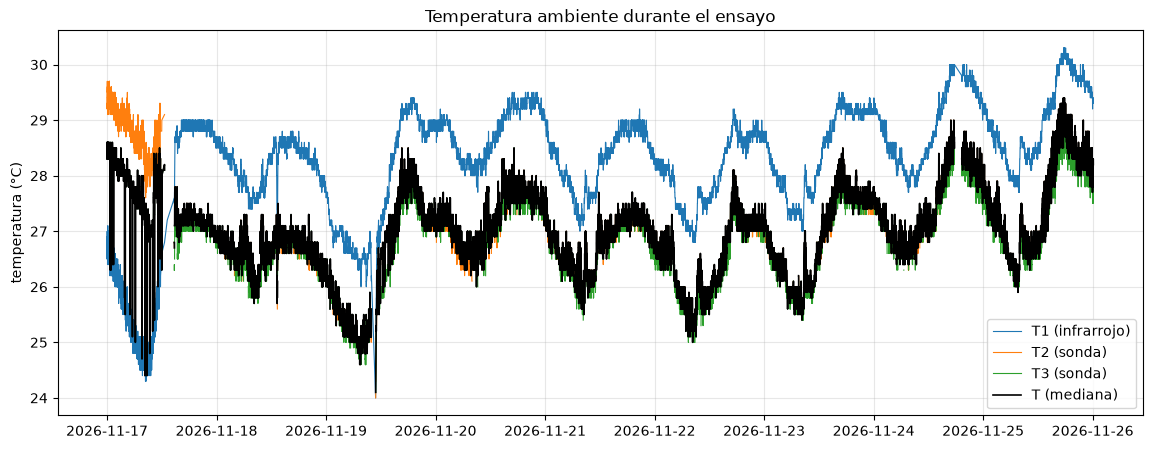

In [24]:
import re

carpeta_temperatura = carpeta.parent / "Temperatura"
patron_de_temperatura = re.compile(r"(T\d?)=(-?\d+(?:\.\d+)?)")


def leer_archivo_de_temperatura(ruta):
    filas = []
    with open(ruta, encoding="utf-8", errors="ignore") as archivo_abierto:
        for linea in archivo_abierto:
            linea = linea.strip()
            if "T=" not in linea:
                continue
            fecha_hora = linea.split(",")[0]
            fila = {"fecha_hora": fecha_hora}
            for nombre, valor in patron_de_temperatura.findall(linea):
                fila[nombre] = float(valor)
            filas.append(fila)
    return pd.DataFrame(filas)


archivos_de_temperatura = sorted(carpeta_temperatura.rglob("*.txt"))
print(f"Archivos de temperatura: {len(archivos_de_temperatura)}")

partes = []
for ruta in archivos_de_temperatura:
    parte = leer_archivo_de_temperatura(ruta)
    parte["origen"] = ruta.name
    partes.append(parte)

temperatura = pd.concat(partes, ignore_index=True)
temperatura["fecha_hora"] = pd.to_datetime(temperatura["fecha_hora"], errors="coerce")
temperatura = temperatura.dropna(subset=["fecha_hora"])
temperatura = temperatura.sort_values("fecha_hora").reset_index(drop=True)

# Valores imposibles para una temperatura ambiente (-255 del conversor, 0 por fallo de lectura)
for columna in ["T", "T1", "T2", "T3"]:
    es_valido = temperatura[columna].between(10, 45)
    temperatura[columna] = temperatura[columna].where(es_valido)

segundos_entre_muestras = temperatura["fecha_hora"].diff().dt.total_seconds()

print(f"Filas: {len(temperatura)}")
print(f"Primera: {temperatura['fecha_hora'].iloc[0]}")
print(f"Última:  {temperatura['fecha_hora'].iloc[-1]}")
print(f"Tiempo típico entre muestras: {segundos_entre_muestras.median():.0f} s")
print(f"Huecos de más de 10 min: {(segundos_entre_muestras > 600).sum()}")
print("Datos faltantes por columna:")
print(temperatura[["T", "T1", "T2", "T3"]].isna().sum())
print(temperatura[["T", "T1", "T2", "T3"]].describe())

temperatura["segundos_desde_anterior"] = temperatura["fecha_hora"].diff().dt.total_seconds()
huecos = temperatura[temperatura["segundos_desde_anterior"] > 600]
for _, fila in huecos.iterrows():
    minutos = fila["segundos_desde_anterior"] / 60
    print(f"Hueco de {minutos:.0f} min que termina en {fila['fecha_hora']}")

figura, eje = plt.subplots(figsize=(14, 5))
eje.plot(temperatura["fecha_hora"], temperatura["T1"], label="T1 (infrarrojo)", linewidth=0.8)
eje.plot(temperatura["fecha_hora"], temperatura["T2"], label="T2 (sonda)", linewidth=0.8)
eje.plot(temperatura["fecha_hora"], temperatura["T3"], label="T3 (sonda)", linewidth=0.8)
eje.plot(temperatura["fecha_hora"], temperatura["T"], label="T (mediana)", color="black", linewidth=1.2)
eje.set_ylabel("temperatura (°C)")
eje.set_title("Temperatura ambiente durante el ensayo")
eje.legend()
eje.grid(alpha=0.3)
plt.show()

Ciclos completos: 728
Ciclos sin temperatura suficiente:
T_media     19
T1_media    16
dtype: int64
          v_media     T_media    T1_media
count  728.000000  709.000000  712.000000
mean     0.482533   26.898805   28.387676
std      0.005205    0.701142    0.729051
min      0.468442   24.946154   25.483333
25%      0.478530   26.523077   27.992857
50%      0.482333   26.921429   28.475952
75%      0.486703   27.280000   28.909341
max      0.494042   28.866667   30.000000


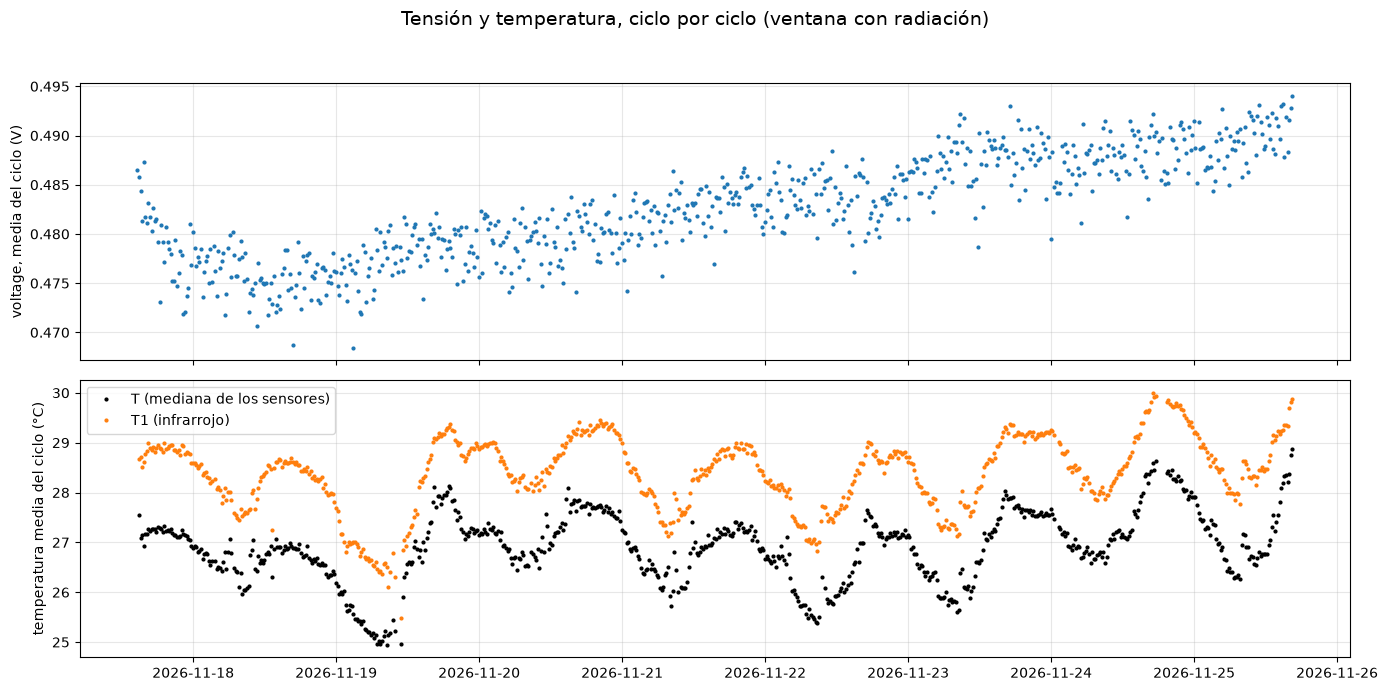

In [25]:
inicio_de_la_ventana = df_con_radiacion["fecha_hora"].min()
fin_de_la_ventana = df_con_radiacion["fecha_hora"].max()
margen = pd.Timedelta(hours=horas_de_margen_en_los_extremos)
muestras_minimas_de_temperatura = 10   # de ~16 esperadas en 8 min

filas = []
for numero, bloque in df_con_radiacion.groupby("numero_de_bloque"):
    esta_prendida = bloque["estado_luz"].iloc[0] == 1
    if not esta_prendida or len(bloque) < 55:
        continue

    inicio = bloque["fecha_hora"].iloc[0]
    fin = bloque["fecha_hora"].iloc[-1]
    if inicio < inicio_de_la_ventana + margen or fin > fin_de_la_ventana - margen:
        continue

    en_el_tramo = (temperatura["fecha_hora"] >= inicio) & (temperatura["fecha_hora"] <= fin)
    temperaturas_del_tramo = temperatura[en_el_tramo]

    fila = {
        "numero_de_bloque": numero,
        "inicio": inicio,
        "v_media": bloque["voltage2"].mean(),
        "v_mediana": bloque["voltage2"].median(),
        "voltage1_mediana": bloque["voltage1"].median(),
    }
    for nombre in ["T", "T1"]:
        valores = temperaturas_del_tramo[nombre].dropna()
        if len(valores) >= muestras_minimas_de_temperatura:
            fila[f"{nombre}_media"] = valores.mean()
        else:
            fila[f"{nombre}_media"] = float("nan")
    filas.append(fila)

ciclos_con_temperatura = pd.DataFrame(filas)

print(f"Ciclos completos: {len(ciclos_con_temperatura)}")
print("Ciclos sin temperatura suficiente:")
print(ciclos_con_temperatura[["T_media", "T1_media"]].isna().sum())
print(ciclos_con_temperatura[["v_media", "T_media", "T1_media"]].describe())

figura, ejes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ejes[0].plot(ciclos_con_temperatura["inicio"], ciclos_con_temperatura["v_media"],
             ".", markersize=4, color="tab:blue")
ejes[0].set_ylabel("voltage, media del ciclo (V)")
ejes[0].grid(alpha=0.3)

ejes[1].plot(ciclos_con_temperatura["inicio"], ciclos_con_temperatura["T_media"],
             ".", markersize=4, color="black", label="T (mediana de los sensores)")
ejes[1].plot(ciclos_con_temperatura["inicio"], ciclos_con_temperatura["T1_media"],
             ".", markersize=4, color="tab:orange", label="T1 (infrarrojo)")
ejes[1].set_ylabel("temperatura media del ciclo (°C)")
ejes[1].legend()
ejes[1].grid(alpha=0.3)

figura.suptitle("Tensión y temperatura, ciclo por ciclo (ventana con radiación)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
figura.savefig(carpeta_graficos / "tension_y_temperatura_por_ciclo.png", dpi=200, bbox_inches="tight")
plt.show()

count    728.000000
mean       6.494388
std        0.070057
min        6.304733
25%        6.440517
50%        6.491689
75%        6.550516
max        6.649282
Name: i_media_uA, dtype: float64


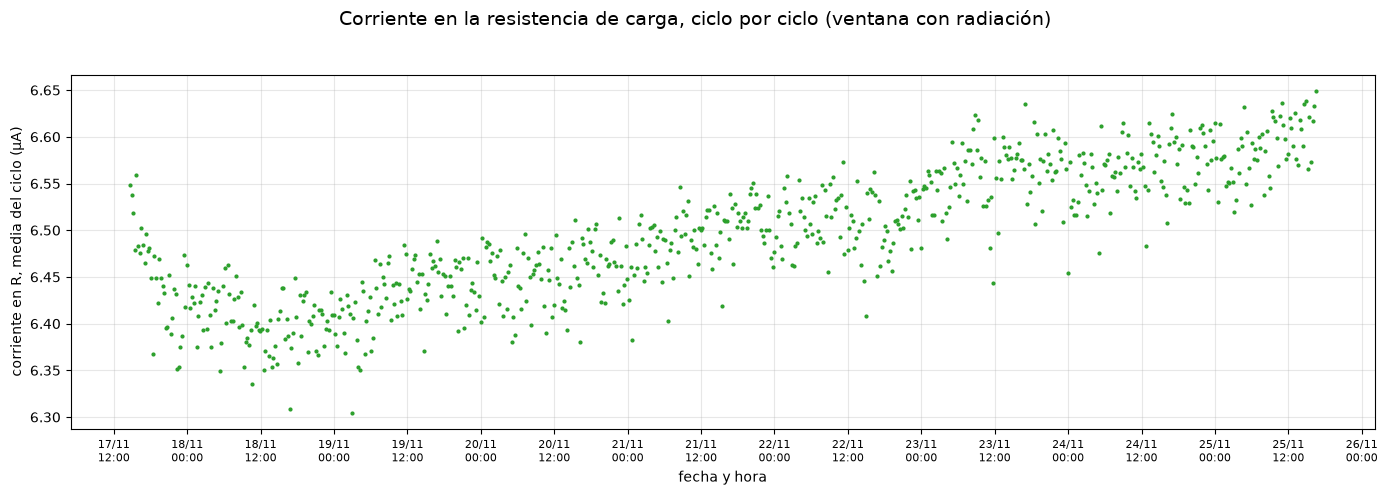

In [26]:
ciclos_con_temperatura["i_media_uA"] = (
    ciclos_con_temperatura["v_media"] / resistencia_de_carga_ohm * 1e6
)

print(ciclos_con_temperatura["i_media_uA"].describe())

figura, eje = plt.subplots(figsize=(14, 5))

eje.plot(ciclos_con_temperatura["inicio"], ciclos_con_temperatura["i_media_uA"],
         ".", markersize=4, color="tab:green")
eje.set_ylabel("corriente en R, media del ciclo (µA)")
eje.set_xlabel("fecha y hora")
eje.grid(alpha=0.3)

eje.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
eje.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
eje.tick_params(axis="x", labelsize=8)

figura.suptitle("Corriente en la resistencia de carga, ciclo por ciclo (ventana con radiación)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
figura.savefig(carpeta_graficos / "corriente_por_ciclo.png", dpi=200, bbox_inches="tight")
plt.show()

Ciclos sin radiación: 189
Ciclos con radiación: 728


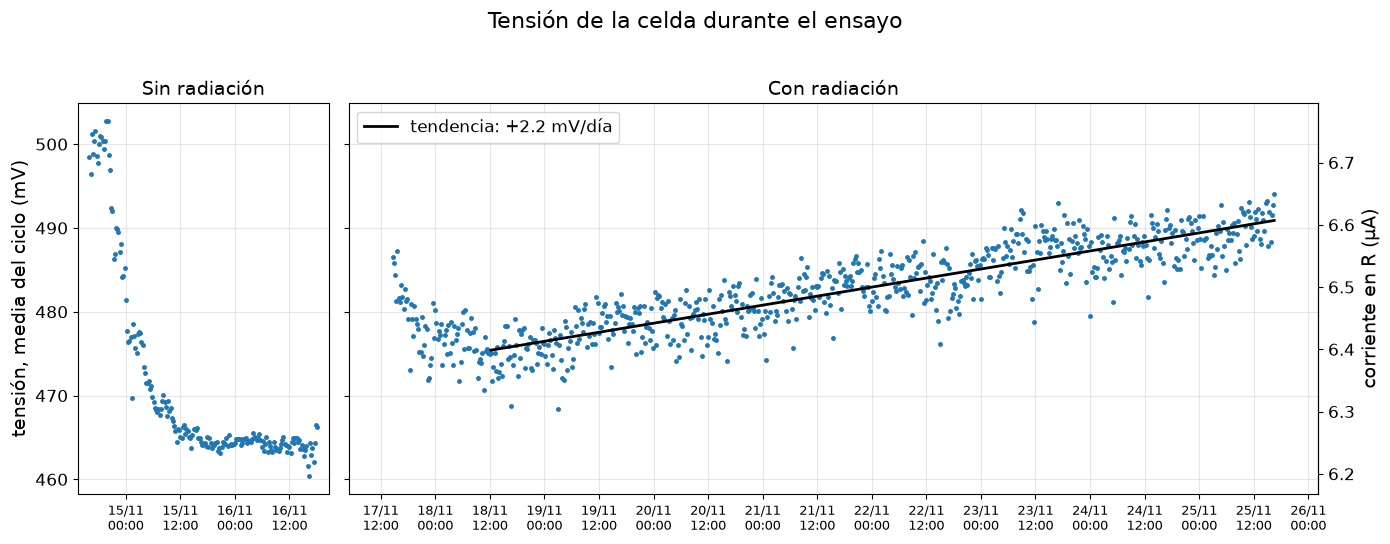

In [28]:
from scipy import stats

#-----------------------------------MEDIA POR CICLO DE CADA VENTANA---------------------------------------#
def calcular_media_por_ciclo(datos, horas_de_margen=horas_de_margen_en_los_extremos):
    inicio_de_la_ventana = datos["fecha_hora"].min()
    fin_de_la_ventana = datos["fecha_hora"].max()
    margen = pd.Timedelta(hours=horas_de_margen)

    filas = []
    for numero, bloque in datos.groupby("numero_de_bloque"):
        esta_prendida = bloque["estado_luz"].iloc[0] == 1
        if not esta_prendida or len(bloque) < 55:
            continue

        inicio = bloque["fecha_hora"].iloc[0]
        fin = bloque["fecha_hora"].iloc[-1]
        if inicio < inicio_de_la_ventana + margen or fin > fin_de_la_ventana - margen:
            continue

        filas.append({
            "inicio": inicio,
            "v_media_mV": bloque["voltage2"].mean() * 1000,
        })

    ciclos = pd.DataFrame(filas)
    # Descartamos ciclos inválidos (tensión media menor a 0,3 V)
    ciclos = ciclos[ciclos["v_media_mV"] > 300].reset_index(drop=True)
    return ciclos


ciclos_sin = calcular_media_por_ciclo(df_sin_radiacion)
ciclos_con = calcular_media_por_ciclo(df_con_radiacion)
print(f"Ciclos sin radiación: {len(ciclos_sin)}")
print(f"Ciclos con radiación: {len(ciclos_con)}")

#-----------------------------------TENDENCIA CON RADIACIÓN---------------------------------------#
inicio_del_ajuste = pd.Timestamp("2026-11-18 12:00:00")
para_ajustar = ciclos_con[ciclos_con["inicio"] >= inicio_del_ajuste]
dias = (para_ajustar["inicio"] - inicio_del_ajuste).dt.total_seconds() / 86400
ajuste = stats.linregress(dias, para_ajustar["v_media_mV"])

dias_de_la_recta = [dias.min(), dias.max()]
fechas_de_la_recta = [inicio_del_ajuste + pd.Timedelta(days=d) for d in dias_de_la_recta]
valores_de_la_recta = [ajuste.intercept + ajuste.slope * d for d in dias_de_la_recta]

#-----------------------------------GRÁFICO PRINCIPAL---------------------------------------#
resistencia_en_kohm = resistencia_de_carga_ohm / 1000

def mv_a_ua(valor_mv):
    return valor_mv / resistencia_en_kohm      # mV / kΩ = µA

def ua_a_mv(valor_ua):
    return valor_ua * resistencia_en_kohm

ancho_sin = (ciclos_sin["inicio"].max() - ciclos_sin["inicio"].min()).total_seconds() / 86400
ancho_con = (ciclos_con["inicio"].max() - ciclos_con["inicio"].min()).total_seconds() / 86400

figura, ejes = plt.subplots(
    1, 2, figsize=(14, 5.5), sharey=True,
    gridspec_kw={"width_ratios": [max(ancho_sin, 1.5), ancho_con]},
)

ventanas = [
    ("Sin radiación", ciclos_sin, ejes[0]),
    ("Con radiación", ciclos_con, ejes[1]),
]

for titulo, ciclos, eje in ventanas:
    eje.plot(ciclos["inicio"], ciclos["v_media_mV"], ".", markersize=5, color="tab:blue")
    eje.set_title(titulo, fontsize=14)
    #eje.set_xlabel("fecha y hora", fontsize=12)
    eje.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
    eje.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
    eje.tick_params(axis="x", labelsize=9)
    eje.tick_params(axis="y", labelsize=12)
    eje.grid(alpha=0.3)

ejes[1].plot(fechas_de_la_recta, valores_de_la_recta, color="black", linewidth=2,
             label=f"tendencia: {ajuste.slope:+.1f} mV/día")
ejes[1].legend(fontsize=12, loc="upper left")

ejes[0].set_ylabel("tensión, media del ciclo (mV)", fontsize=14)

eje_corriente = ejes[1].secondary_yaxis("right", functions=(mv_a_ua, ua_a_mv))
eje_corriente.set_ylabel("corriente en R (µA)", fontsize=14)
eje_corriente.tick_params(labelsize=12)

figura.suptitle("Tensión de la celda durante el ensayo", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
figura.savefig(carpeta_graficos / "resultado_principal.png", dpi=200, bbox_inches="tight")
plt.show()

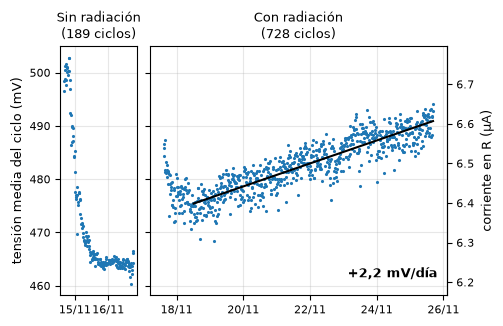

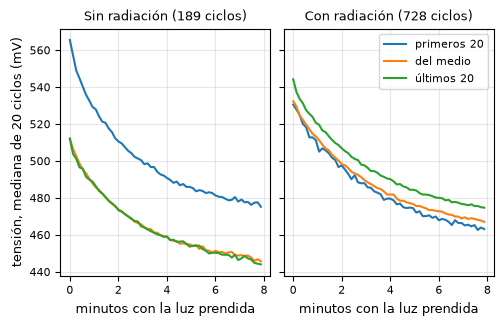

In [35]:
#-----------------------------------FIGURAS COMPACTAS PARA LA DIAPO---------------------------------------#
centimetros = 1 / 2.54
ancho_de_figura = 12.5 * centimetros
alto_de_figura = 8.0 * centimetros

estilo_compacto = {
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
}


def calcular_perfiles_medianos(datos, ciclos_por_grupo=20, horas_de_margen=horas_de_margen_en_los_extremos):
    inicio_de_la_ventana = datos["fecha_hora"].min()
    fin_de_la_ventana = datos["fecha_hora"].max()
    margen = pd.Timedelta(hours=horas_de_margen)

    bloques_elegibles = []
    for numero, bloque in datos.groupby("numero_de_bloque"):
        esta_prendida = bloque["estado_luz"].iloc[0] == 1
        if not esta_prendida or len(bloque) < 55:
            continue

        inicio = bloque["fecha_hora"].iloc[0]
        fin = bloque["fecha_hora"].iloc[-1]
        if inicio < inicio_de_la_ventana + margen or fin > fin_de_la_ventana - margen:
            continue

        bloques_elegibles.append(bloque)

    cantidad_de_ciclos = len(bloques_elegibles)
    inicio_del_medio = cantidad_de_ciclos // 2 - ciclos_por_grupo // 2
    grupos = {
        "primeros 20": bloques_elegibles[:ciclos_por_grupo],
        "del medio": bloques_elegibles[inicio_del_medio:inicio_del_medio + ciclos_por_grupo],
        "últimos 20": bloques_elegibles[-ciclos_por_grupo:],
    }

    perfiles = {}
    for nombre, bloques in grupos.items():
        partes = []
        for bloque in bloques:
            parte = bloque[["voltage2", "minutos_desde_inicio_de_bloque"]].copy()
            parte["posicion"] = range(len(parte))
            partes.append(parte)
        juntos = pd.concat(partes)

        perfil = juntos.groupby("posicion").agg(
            tension=("voltage2", "median"),
            minutos=("minutos_desde_inicio_de_bloque", "median"),
            cantidad=("voltage2", "size"),
        )
        # Solo posiciones donde hay al menos la mitad de los ciclos del grupo
        perfil = perfil[perfil["cantidad"] >= len(bloques) / 2]
        perfiles[nombre] = perfil

    return perfiles, cantidad_de_ciclos


#-----------------------------------FIGURA A: TENSIÓN POR CICLO---------------------------------------#
with plt.rc_context(estilo_compacto):
    figura_a, ejes_a = plt.subplots(
        1, 2, figsize=(ancho_de_figura, alto_de_figura), sharey=True,
        layout="constrained",
        gridspec_kw={"width_ratios": [max(ancho_sin, 1.5), ancho_con]},
    )

    ventanas_a = [
        ("Sin radiación", ciclos_sin, ejes_a[0], 1),
        ("Con radiación", ciclos_con, ejes_a[1], 2),
    ]
    for titulo, ciclos, eje, dias_entre_marcas in ventanas_a:
        eje.plot(ciclos["inicio"], ciclos["v_media_mV"], ".", markersize=2.5, color="tab:blue")
        eje.set_title(f"{titulo}\n({len(ciclos)} ciclos)")
        eje.xaxis.set_major_locator(mdates.DayLocator(interval=dias_entre_marcas))
        eje.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
        eje.grid(alpha=0.3)

    ejes_a[1].plot(fechas_de_la_recta, valores_de_la_recta, color="black", linewidth=1.5)
    texto_de_tendencia = f"{ajuste.slope:+.1f}".replace(".", ",") + " mV/día"
    ejes_a[1].text(0.97, 0.06, texto_de_tendencia, transform=ejes_a[1].transAxes,
                   ha="right", va="bottom", fontsize=9, fontweight="bold")

    ejes_a[0].set_ylabel("tensión media del ciclo (mV)")

    eje_corriente = ejes_a[1].secondary_yaxis("right", functions=(mv_a_ua, ua_a_mv))
    eje_corriente.set_ylabel("corriente en R (µA)")

    figura_a.savefig(carpeta_graficos / "figura_tension_compacta.png", dpi=300)
    plt.show()


#-----------------------------------FIGURA B: PERFIL MEDIANO DENTRO DEL CICLO---------------------------------------#
perfiles_sin, cantidad_sin = calcular_perfiles_medianos(df_sin_radiacion)
perfiles_con, cantidad_con = calcular_perfiles_medianos(df_con_radiacion)

colores_de_los_grupos = {
    "primeros 20": "tab:blue",
    "del medio": "tab:orange",
    "últimos 20": "tab:green",
}

with plt.rc_context(estilo_compacto):
    figura_b, ejes_b = plt.subplots(
        1, 2, figsize=(ancho_de_figura, alto_de_figura), sharey=True,
        layout="constrained",
    )

    ventanas_b = [
        (f"Sin radiación ({cantidad_sin} ciclos)", perfiles_sin, ejes_b[0]),
        (f"Con radiación ({cantidad_con} ciclos)", perfiles_con, ejes_b[1]),
    ]
    for titulo, perfiles, eje in ventanas_b:
        for nombre, perfil in perfiles.items():
            eje.plot(perfil["minutos"], perfil["tension"] * 1000,
                     linewidth=1.5, color=colores_de_los_grupos[nombre], label=nombre)
        eje.set_title(titulo)
        eje.set_xlabel("minutos con la luz prendida")
        eje.grid(alpha=0.3)

    ejes_b[0].set_ylabel("tensión, mediana de 20 ciclos (mV)")
    ejes_b[1].legend(loc="upper right")

    figura_b.savefig(carpeta_graficos / "figura_perfil_compacta.png", dpi=300)
    plt.show()

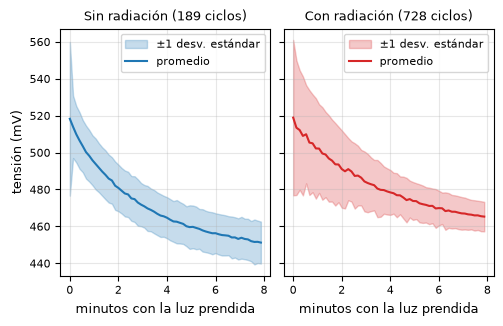

In [31]:

#-----------------------------------PERFIL PROMEDIO ± DESVIACIÓN ESTÁNDAR---------------------------------------#
def calcular_perfil_promedio(datos, horas_de_margen=horas_de_margen_en_los_extremos):
    inicio_de_la_ventana = datos["fecha_hora"].min()
    fin_de_la_ventana = datos["fecha_hora"].max()
    margen = pd.Timedelta(hours=horas_de_margen)

    perfiles_de_los_ciclos = []
    for numero, bloque in datos.groupby("numero_de_bloque"):
        esta_prendida = bloque["estado_luz"].iloc[0] == 1
        if not esta_prendida or len(bloque) < 55:
            continue

        inicio = bloque["fecha_hora"].iloc[0]
        fin = bloque["fecha_hora"].iloc[-1]
        if inicio < inicio_de_la_ventana + margen or fin > fin_de_la_ventana - margen:
            continue

        tension_del_ciclo_mV = bloque["voltage2"] * 1000
        if tension_del_ciclo_mV.mean() <= 300:      # ciclo inválido
            continue

        parte = pd.DataFrame({
            "tension_mV": tension_del_ciclo_mV.values,
            "minutos": bloque["minutos_desde_inicio_de_bloque"].values,
        })
        parte["posicion"] = range(len(parte))
        perfiles_de_los_ciclos.append(parte)

    cantidad_de_ciclos = len(perfiles_de_los_ciclos)
    juntos = pd.concat(perfiles_de_los_ciclos)

    perfil = juntos.groupby("posicion").agg(
        minutos=("minutos", "mean"),
        tension_media=("tension_mV", "mean"),
        desvio=("tension_mV", "std"),
        tension_minima=("tension_mV", "min"),
        tension_maxima=("tension_mV", "max"),
        cantidad=("tension_mV", "size"),
    )
    # Solo posiciones donde hay al menos la mitad de los ciclos
    perfil = perfil[perfil["cantidad"] >= cantidad_de_ciclos / 2]
    return perfil, cantidad_de_ciclos


mostrar_maximos_y_minimos = False   # True para agregar líneas punteadas con mínimo y máximo

perfil_sin, cantidad_sin = calcular_perfil_promedio(df_sin_radiacion)
perfil_con, cantidad_con = calcular_perfil_promedio(df_con_radiacion)

with plt.rc_context(estilo_compacto):
    figura_c, ejes_c = plt.subplots(
        1, 2, figsize=(ancho_de_figura, alto_de_figura), sharey=True,
        layout="constrained",
    )

    ventanas_c = [
        (f"Sin radiación ({cantidad_sin} ciclos)", perfil_sin, "tab:blue", ejes_c[0]),
        (f"Con radiación ({cantidad_con} ciclos)", perfil_con, "tab:red", ejes_c[1]),
    ]
    for titulo, perfil, color, eje in ventanas_c:
        limite_inferior_de_la_banda = perfil["tension_media"] - perfil["desvio"]
        limite_superior_de_la_banda = perfil["tension_media"] + perfil["desvio"]

        eje.fill_between(perfil["minutos"], limite_inferior_de_la_banda, limite_superior_de_la_banda,
                         color=color, alpha=0.25, label="±1 desv. estándar")
        eje.plot(perfil["minutos"], perfil["tension_media"],
                 color=color, linewidth=1.5, label="promedio")

        if mostrar_maximos_y_minimos:
            eje.plot(perfil["minutos"], perfil["tension_maxima"], color=color, linestyle=":", linewidth=0.8)
            eje.plot(perfil["minutos"], perfil["tension_minima"], color=color, linestyle=":", linewidth=0.8)

        eje.set_title(titulo)
        eje.set_xlabel("minutos con la luz prendida")
        eje.grid(alpha=0.3)
        eje.legend(loc="upper right")

    ejes_c[0].set_ylabel("tensión (mV)")

    figura_c.savefig(carpeta_graficos / "figura_perfil_promedio_std.png", dpi=300)
    plt.show()

Sin radiación
       muestra_0  muestra_1  muestra_2  muestra_3  muestra_4  muestra_5
count      189.0      189.0      189.0      189.0      189.0      189.0
mean       518.3      513.9      509.9      506.5      503.5      500.2
std         41.6       16.9       15.3       15.3       14.1       14.4
min          1.8      471.6      490.1      473.8      483.5      469.5
5%         507.3      501.3      497.3      493.6      493.4      488.4
50%        514.7      507.3      502.9      499.8      496.7      494.1
95%        565.5      557.3      548.8      544.7      540.3      535.8
max        583.7      565.7      557.4      552.1      545.9      545.1

Con radiación
       muestra_0  muestra_1  muestra_2  muestra_3  muestra_4  muestra_5
count      728.0      728.0      728.0      728.0      728.0      728.0
mean       518.9      513.5      512.2      509.0      509.9      505.4
std         42.1       36.5       32.4       32.2       26.6       28.4
min          0.9      385.9      38

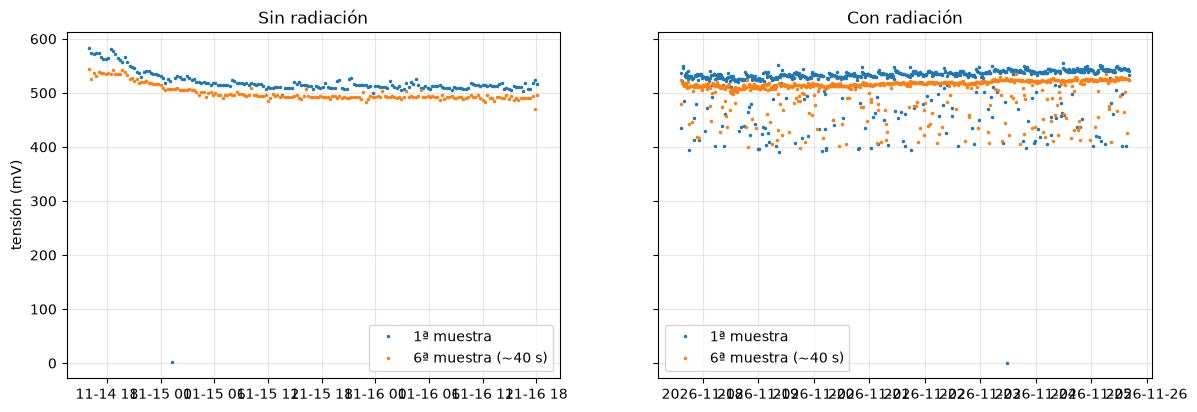

In [32]:
def tensiones_de_las_primeras_muestras(datos, cantidad_de_posiciones=6,
                                       horas_de_margen=horas_de_margen_en_los_extremos):
    inicio_de_la_ventana = datos["fecha_hora"].min()
    fin_de_la_ventana = datos["fecha_hora"].max()
    margen = pd.Timedelta(hours=horas_de_margen)

    filas = []
    for numero, bloque in datos.groupby("numero_de_bloque"):
        esta_prendida = bloque["estado_luz"].iloc[0] == 1
        if not esta_prendida or len(bloque) < 55:
            continue
        inicio = bloque["fecha_hora"].iloc[0]
        fin = bloque["fecha_hora"].iloc[-1]
        if inicio < inicio_de_la_ventana + margen or fin > fin_de_la_ventana - margen:
            continue
        tension_mV = bloque["voltage2"] * 1000
        if tension_mV.mean() <= 300:
            continue

        fila = {"inicio": inicio}
        for posicion in range(cantidad_de_posiciones):
            fila[f"muestra_{posicion}"] = tension_mV.iloc[posicion]
        filas.append(fila)
    return pd.DataFrame(filas)


figura_d, ejes_d = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for eje, (titulo, datos) in zip(ejes_d, [("Sin radiación", df_sin_radiacion),
                                         ("Con radiación", df_con_radiacion)]):
    primeras = tensiones_de_las_primeras_muestras(datos)
    columnas_de_muestras = [c for c in primeras.columns if c.startswith("muestra_")]

    print(titulo)
    print(primeras[columnas_de_muestras].describe(percentiles=[0.05, 0.5, 0.95]).round(1))
    print()

    eje.plot(primeras["inicio"], primeras["muestra_0"], ".", markersize=3, label="1ª muestra")
    eje.plot(primeras["inicio"], primeras["muestra_5"], ".", markersize=3, label="6ª muestra (~40 s)")
    eje.set_title(titulo)
    eje.grid(alpha=0.3)
    eje.legend()
ejes_d[0].set_ylabel("tensión (mV)")
plt.show()

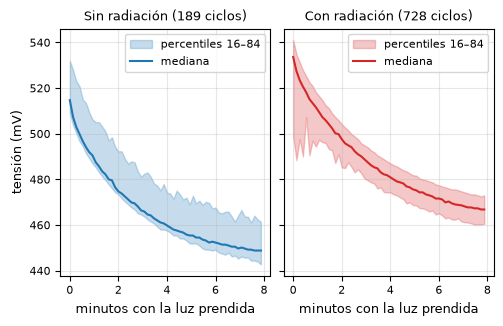

In [33]:
#-----------------------------------PERFIL MEDIANO CON BANDA DE PERCENTILES 16-84---------------------------------------#
def calcular_perfil_robusto(datos, horas_de_margen=horas_de_margen_en_los_extremos):
    inicio_de_la_ventana = datos["fecha_hora"].min()
    fin_de_la_ventana = datos["fecha_hora"].max()
    margen = pd.Timedelta(hours=horas_de_margen)

    perfiles_de_los_ciclos = []
    for numero, bloque in datos.groupby("numero_de_bloque"):
        esta_prendida = bloque["estado_luz"].iloc[0] == 1
        if not esta_prendida or len(bloque) < 55:
            continue

        inicio = bloque["fecha_hora"].iloc[0]
        fin = bloque["fecha_hora"].iloc[-1]
        if inicio < inicio_de_la_ventana + margen or fin > fin_de_la_ventana - margen:
            continue

        tension_mV = bloque["voltage2"] * 1000
        # Lecturas en 0 mV (fallos del ADC): se ignoran muestra a muestra
        tension_mV = tension_mV.where(tension_mV > 300)
        if tension_mV.mean() <= 300 or tension_mV.isna().all():
            continue

        parte = pd.DataFrame({
            "tension_mV": tension_mV.values,
            "minutos": bloque["minutos_desde_inicio_de_bloque"].values,
        })
        parte["posicion"] = range(len(parte))
        perfiles_de_los_ciclos.append(parte)

    cantidad_de_ciclos = len(perfiles_de_los_ciclos)
    juntos = pd.concat(perfiles_de_los_ciclos)
    por_posicion = juntos.groupby("posicion")["tension_mV"]

    perfil = pd.DataFrame({
        "minutos": juntos.groupby("posicion")["minutos"].mean(),
        "mediana": por_posicion.median(),
        "percentil_16": por_posicion.quantile(0.16),
        "percentil_84": por_posicion.quantile(0.84),
        "cantidad": por_posicion.count(),
    })
    perfil = perfil[perfil["cantidad"] >= cantidad_de_ciclos / 2]
    return perfil, cantidad_de_ciclos


perfil_sin, cantidad_sin = calcular_perfil_robusto(df_sin_radiacion)
perfil_con, cantidad_con = calcular_perfil_robusto(df_con_radiacion)

with plt.rc_context(estilo_compacto):
    figura_e, ejes_e = plt.subplots(1, 2, figsize=(ancho_de_figura, alto_de_figura),
                                    sharey=True, layout="constrained")
    ventanas_e = [
        (f"Sin radiación ({cantidad_sin} ciclos)", perfil_sin, "tab:blue", ejes_e[0]),
        (f"Con radiación ({cantidad_con} ciclos)", perfil_con, "tab:red", ejes_e[1]),
    ]
    for titulo, perfil, color, eje in ventanas_e:
        eje.fill_between(perfil["minutos"], perfil["percentil_16"], perfil["percentil_84"],
                         color=color, alpha=0.25, label="percentiles 16–84")
        eje.plot(perfil["minutos"], perfil["mediana"], color=color, linewidth=1.5, label="mediana")
        eje.set_title(titulo)
        eje.set_xlabel("minutos con la luz prendida")
        eje.grid(alpha=0.3)
        eje.legend(loc="upper right")
    ejes_e[0].set_ylabel("tensión (mV)")
    figura_e.savefig(carpeta_graficos / "figura_perfil_mediana_percentiles.png", dpi=300)
    plt.show()